# Explore here

In [113]:
from utils import db_connect
engine = db_connect()


URL= "https://breathecode.herokuapp.com/asset/internal-link?id=930&path=diabetes.csv"

import pandas as pd

total_data = pd.read_csv("https://breathecode.herokuapp.com/asset/internal-link?id=930&path=diabetes.csv")
total_data.head()

train_data = pd.read_csv ("https://breathecode.herokuapp.com/asset/internal-link?id=930&path=diabetes.csv")
test_data = pd.read_csv ("https://breathecode.herokuapp.com/asset/internal-link?id=930&path=diabetes.csv")
test_diabetes_data = pd.read_csv ("https://breathecode.herokuapp.com/asset/internal-link?id=930&path=diabetes.csv")
test_data["Outcome"] = test_diabetes_data["Outcome"]

total_data = pd.concat([train_data, test_data]).reset_index(inplace = False)
total_data.drop(columns = ["index"], inplace = True)
total_data.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [83]:
# Obtener las dimensiones
total_data.shape

(1536, 9)

In [84]:
# Obtener información sobre tipos de datos y valores no nulos
total_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1536 entries, 0 to 1535
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               1536 non-null   int64  
 1   Glucose                   1536 non-null   int64  
 2   BloodPressure             1536 non-null   int64  
 3   SkinThickness             1536 non-null   int64  
 4   Insulin                   1536 non-null   int64  
 5   BMI                       1536 non-null   float64
 6   DiabetesPedigreeFunction  1536 non-null   float64
 7   Age                       1536 non-null   int64  
 8   Outcome                   1536 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 108.1 KB


Todas variables numericas
No hay valores nulos, sin datos
No hay duplicados
Toda la información es relevante, no hay que eliminar nada

•  El objetivo es predecir en base a medidas diagnósticas si un paciente tiene o no diabetes.

La variable Outcome (0 o 1) es la que define si el paciente tiene o no diabetes

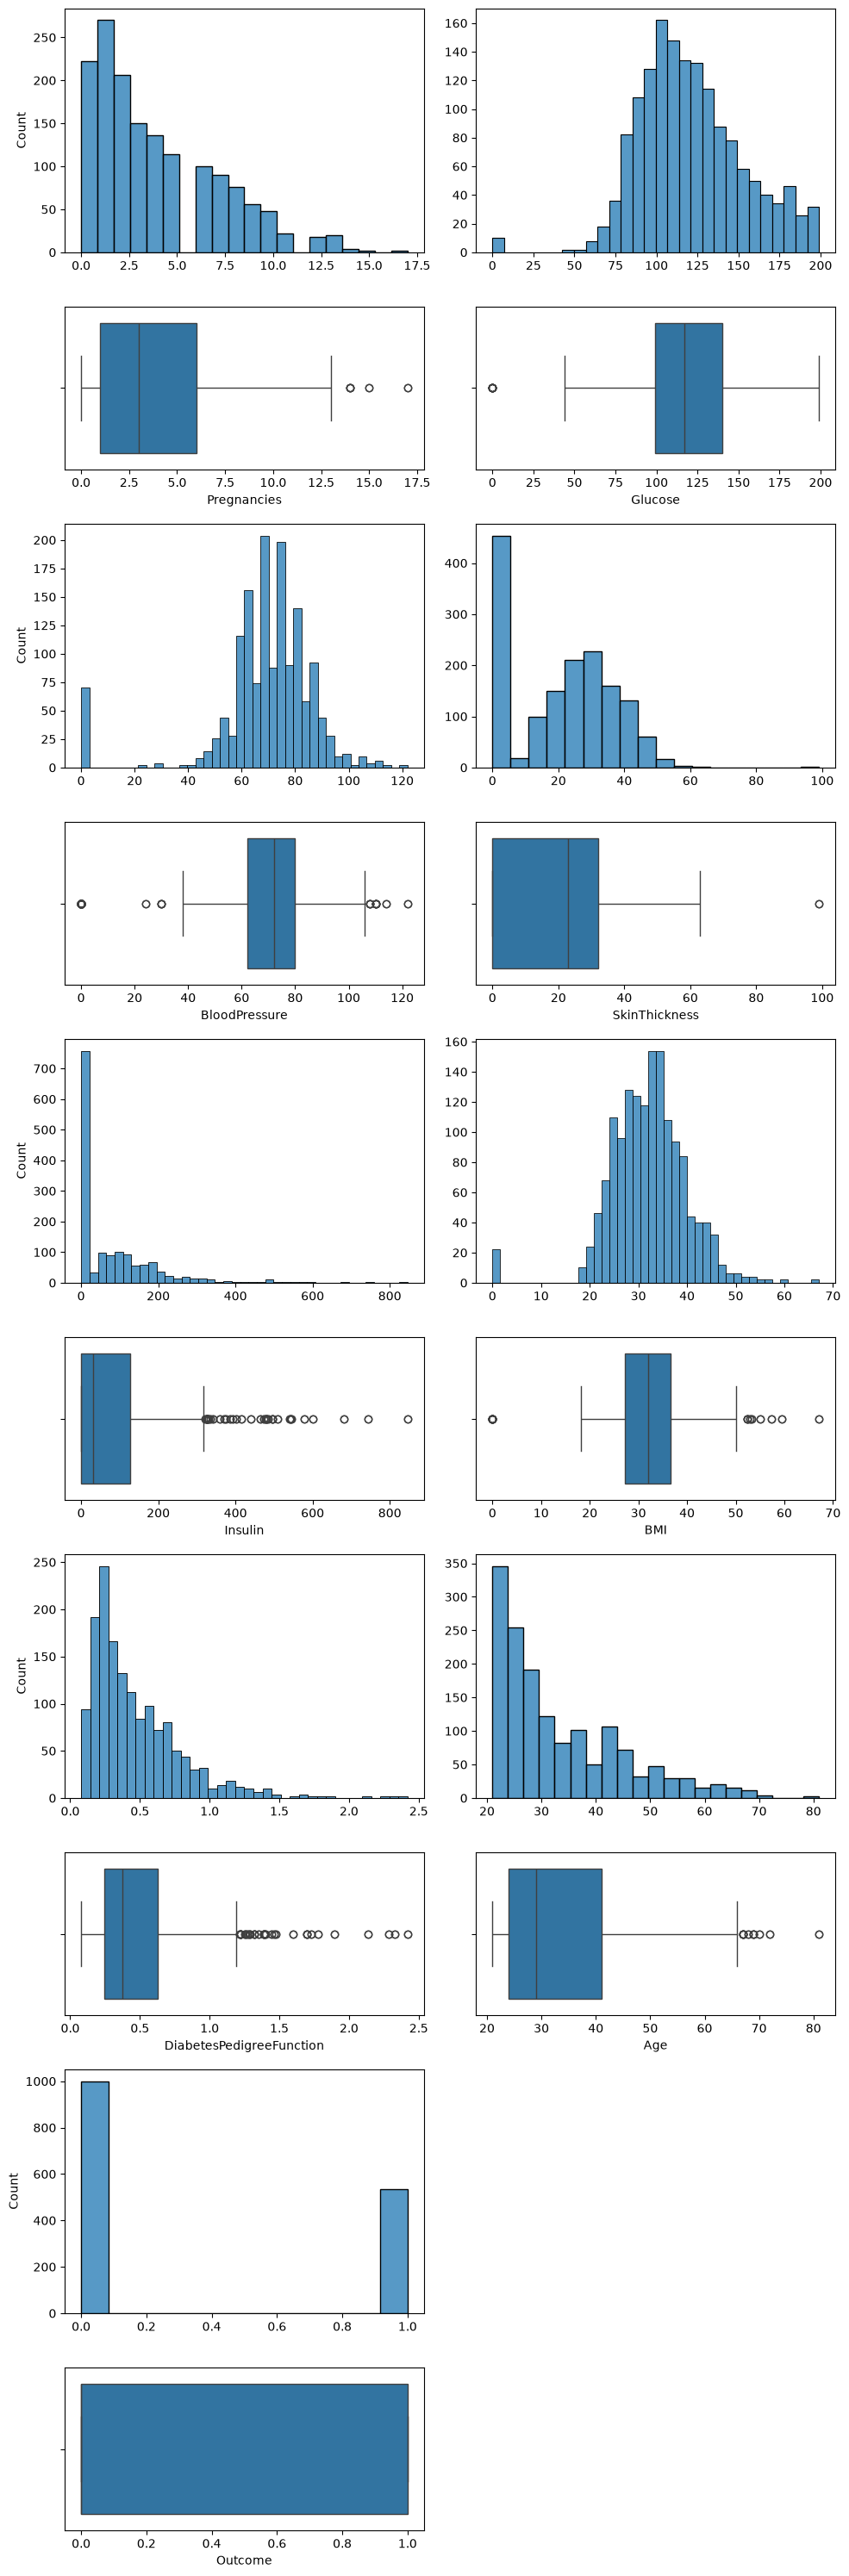

In [85]:
# Análisis sobre variables numéricas
import matplotlib.pyplot as plt 
import seaborn as sns

fig, axis = plt.subplots(10, 2, figsize = (10, 30), gridspec_kw={'height_ratios': [3, 2, 3, 2, 3, 2, 3, 2, 3, 2]})

# Crear una figura múltiple con histogramas y diagramas de caja
sns.histplot(ax = axis[0, 0], data = total_data, x = "Pregnancies").set(xlabel = None)
sns.boxplot(ax = axis[1, 0], data = total_data, x = "Pregnancies")
sns.histplot(ax = axis[0, 1], data = total_data, x = "Glucose").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[1, 1], data = total_data, x = "Glucose")

sns.histplot(ax = axis[2, 0], data = total_data, x = "BloodPressure").set(xlabel = None)
sns.boxplot(ax = axis[3, 0], data = total_data, x = "BloodPressure")
sns.histplot(ax = axis[2, 1], data = total_data, x = "SkinThickness").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[3, 1], data = total_data, x = "SkinThickness")


sns.histplot(ax = axis[4, 0], data = total_data, x = "Insulin").set(xlabel = None)
sns.boxplot(ax = axis[5, 0], data = total_data, x = "Insulin")
sns.histplot(ax = axis[4, 1], data = total_data, x = "BMI").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[5, 1], data = total_data, x = "BMI")


sns.histplot(ax = axis[6, 0], data = total_data, x = "DiabetesPedigreeFunction").set(xlabel = None)
sns.boxplot(ax = axis[7, 0], data = total_data, x = "DiabetesPedigreeFunction")
sns.histplot(ax = axis[6, 1], data = total_data, x = "Age").set(xlabel = None, ylabel = None)
sns.boxplot(ax = axis[7, 1], data = total_data, x = "Age")


sns.histplot(ax = axis[8, 0], data = total_data, x = "Outcome").set(xlabel = None)
sns.boxplot(ax = axis[9, 0], data = total_data, x = "Outcome")


# Ajustar el layout
plt.tight_layout()
fig.delaxes(axis[9, 1])
fig.delaxes(axis[8,1])

# Mostrar el plot
plt.show()

# Conclusiones
Con la representación de cada variable numerica y su gráfico de caja podemos determinar que:

• Pregnancies: El promedio de hijos por persona es de 3

• Glucose: La Concentración de glucosa en plasma va mayormente de 100 y 140 con un valor medi0 de 115

• BloodPressure: La Presión arterial (medida en mm Hg) va de 60 a 80 con un valor de 70 de media, o sea con valores considerables normales de presion sanguínea. Hay hasta 140 personas con valores que superan los 80, o sea con presión alta y aunque sea una persona con el valor maximo de presión que es 120

• SkinThickness: El Grosor del pliegue cutáneo del tríceps (medida en mm) 0 a 30 media 25 mm

• Insulin: La Insulina sérica de 2 horas (medida en mu U/ml) 0 a 110 media de 25 mu U/ml. Cuanta insulina hay en sangre despues de 2hrs. valores normales 30 a 50. Hasta 100 llega la cantidad de personas que sobrepasan 50

• BMI. Índice de masa corporal 27 a 37 media de 32. Si consideramos que 25 es un valor nomal podemos decir que la mayoria de estas personas tienen algun tipo de sobrepeso porque sobrepasan este numero

•  DiabetesPedigreeFunction. Función de pedigrí de diabetes de 0,25 a 0,75 media de 0,375.. indicador o función que mide el riesgo de una persona de desarrollar diabetes basándose en los antecedentes familiares de la enfermedad o sea que >numero mas riesgo a partir de 0,60 es alto.
Entre estas personas hay un valor promedio de 0,37 que representa un riesgo moderado

•  Age de 24 a 41 años media de 29 años. Esta prueba se hizo en gente joven/adulta

•  Outcome. Variable de clase (0 o 1), siendo 0 negativo en diabetes y 1, positivo 1000=0 590=1 o sea que un poco mas de la mitad tendrian diabetes

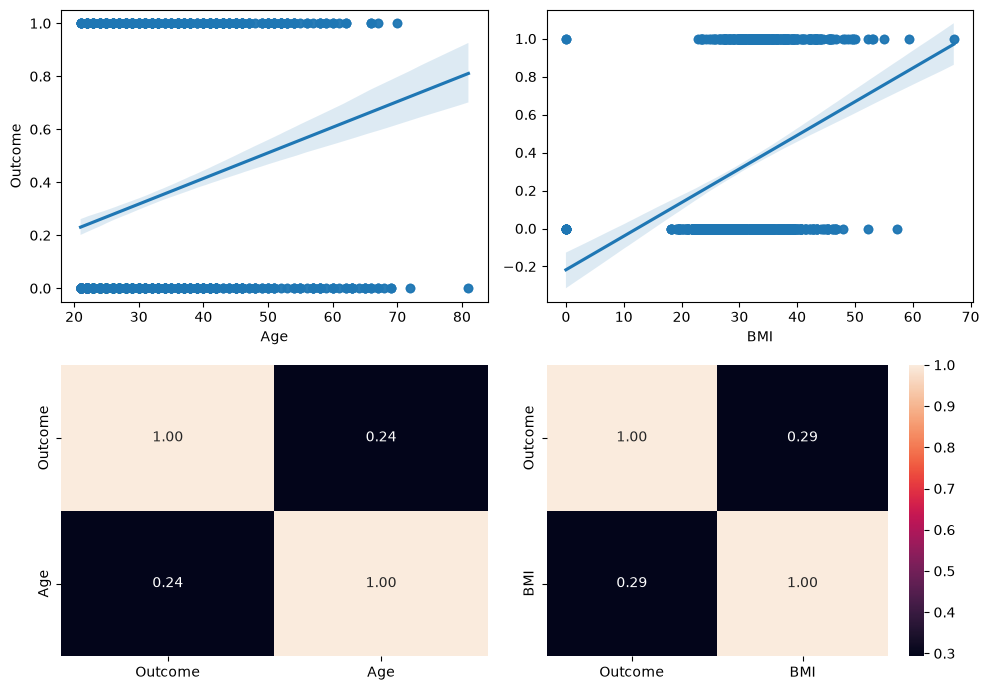

In [112]:
#  Análisis de variables multivariante
#  Análisis numérico-numérico

fig, axis = plt.subplots(2, 2, figsize = (10, 7))

# Crear un diagrama de dispersión múltiple
sns.regplot(ax = axis[0, 0], data = total_data, x = "Age", y = "Outcome")
sns.heatmap(total_data[["Outcome", "Age"]].corr(), annot = True, fmt = ".2f", ax = axis[1, 0], cbar = False)
sns.regplot(ax = axis[0, 1], data = total_data, x = "BMI", y = "Outcome").set(ylabel=None)
sns.heatmap(total_data[["Outcome", "BMI"]].corr(), annot = True, fmt = ".2f", ax = axis[1, 1])

# Ajustar el layout
plt.tight_layout()

# Mostrar el plot
plt.show()

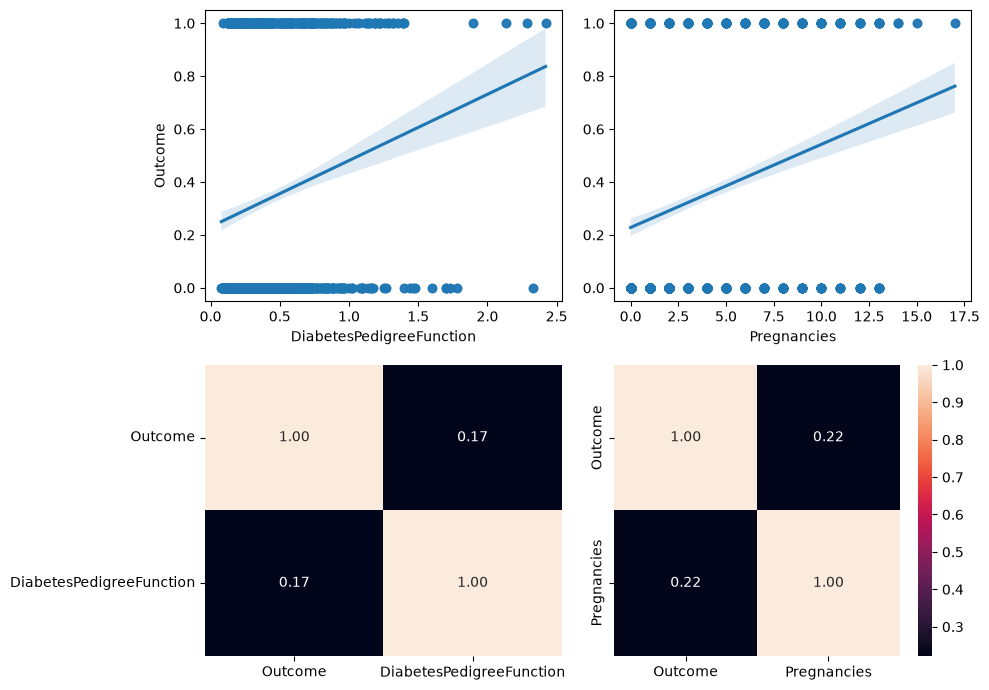

In [87]:
fig, axis = plt.subplots(2, 2, figsize = (10, 7))

# Crear un diagrama de dispersión múltiple
sns.regplot(ax = axis[0, 0], data = total_data, x = "DiabetesPedigreeFunction", y = "Outcome")
sns.heatmap(total_data[["Outcome", "DiabetesPedigreeFunction"]].corr(), annot = True, fmt = ".2f", ax = axis[1, 0], cbar = False)
sns.regplot(ax = axis[0, 1], data = total_data, x = "Pregnancies", y = "Outcome").set(ylabel=None)
sns.heatmap(total_data[["Outcome", "Pregnancies"]].corr(), annot = True, fmt = ".2f", ax = axis[1, 1])

# Ajustar el layout
plt.tight_layout()

# Mostrar el plot
plt.show()

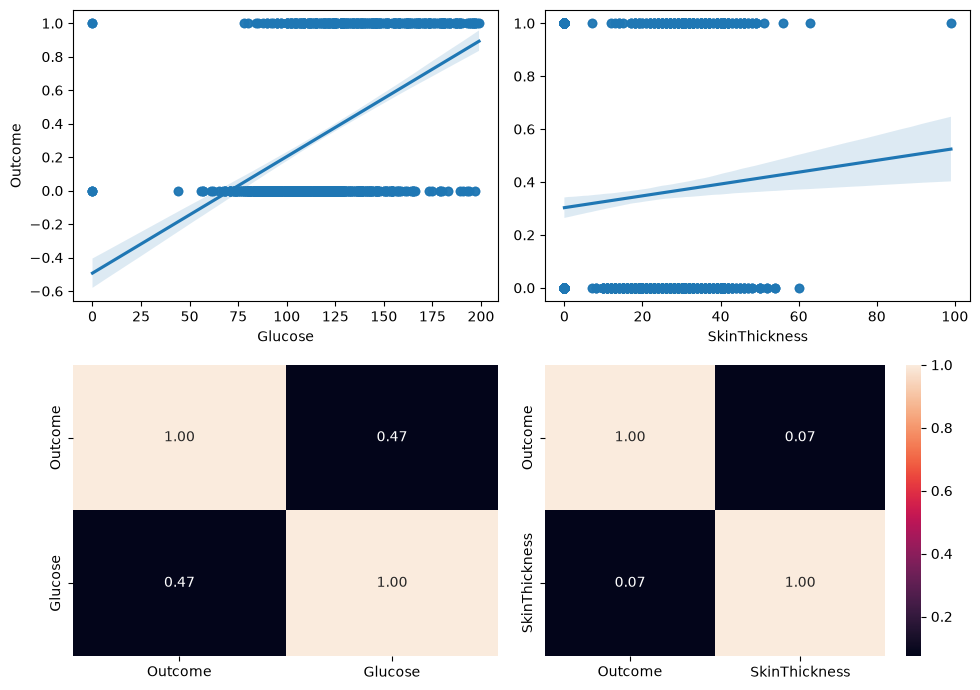

In [88]:
# Crear un diagrama de dispersión múltiple
fig, axis = plt.subplots(2, 2, figsize = (10, 7))

sns.regplot(ax = axis[0, 0], data = total_data, x = "Glucose", y = "Outcome")
sns.heatmap(total_data[["Outcome", "Glucose"]].corr(), annot = True, fmt = ".2f", ax = axis[1, 0], cbar = False)
sns.regplot(ax = axis[0, 1], data = total_data, x = "SkinThickness", y = "Outcome").set(ylabel=None)
sns.heatmap(total_data[["Outcome", "SkinThickness"]].corr(), annot = True, fmt = ".2f", ax = axis[1, 1])


# Ajustar el layout
plt.tight_layout()

# Mostrar el plot
plt.show()

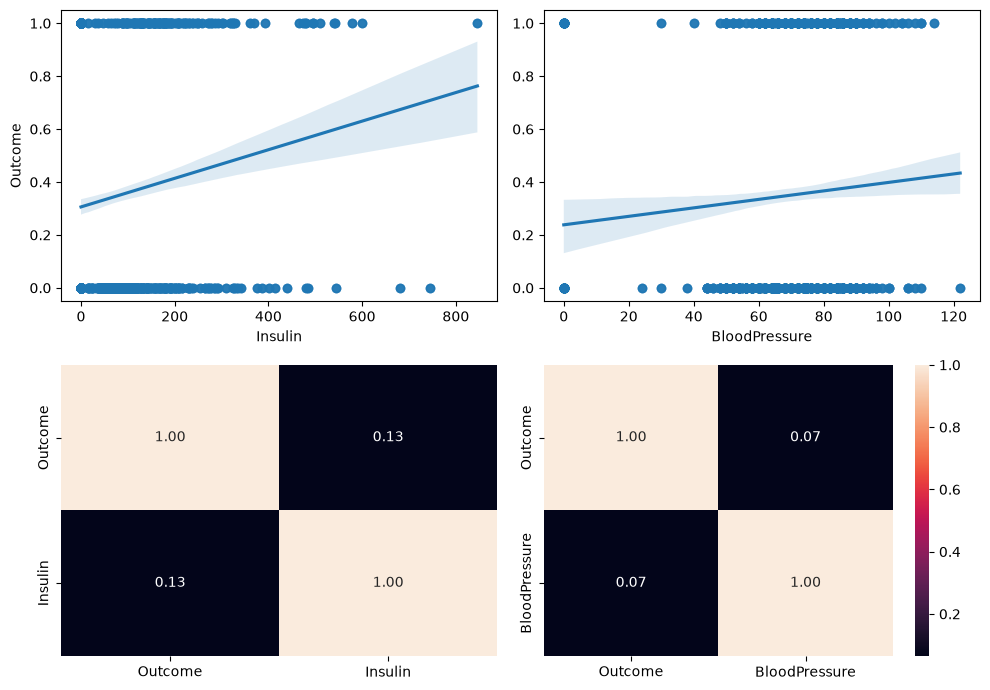

In [89]:
# Crear un diagrama de dispersión múltiple
fig, axis = plt.subplots(2, 2, figsize = (10, 7))

sns.regplot(ax = axis[0, 0], data = total_data, x = "Insulin", y = "Outcome")
sns.heatmap(total_data[["Outcome", "Insulin"]].corr(), annot = True, fmt = ".2f", ax = axis[1, 0], cbar = False)
sns.regplot(ax = axis[0, 1], data = total_data, x = "BloodPressure", y = "Outcome").set(ylabel=None)
sns.heatmap(total_data[["Outcome", "BloodPressure"]].corr(), annot = True, fmt = ".2f", ax = axis[1, 1])


# Ajustar el layout
plt.tight_layout()

# Mostrar el plot
plt.show()

# Conclusiones

Todas las rectas de regresión son positivas, existiendo así relaciones directas entre las variables y Outcome:

Muy relacionadas: Glucose, BMI y Age

Algo relacionadas: Pregnancies y DiabetesPedigreeFunction

Menos: SkinThickness, BloodPressure e Insulin

Los cual podemos traducirlo en que la concentración de glucosa en plasma, el índice de masa corporal y la edad pueden estar muy ligados en tener diabetes o no

Tener mayor cantidad de hijos y el riesgo de antecedentes familiares de la enfermedad no lo son tanto

Y el grosor del pliegue cutáneo del tríceps, tener mas alta o no la presión arterial y saber cuanta insulina hay en sangre despues de 2hrs, no estarían estando tan relacionadas

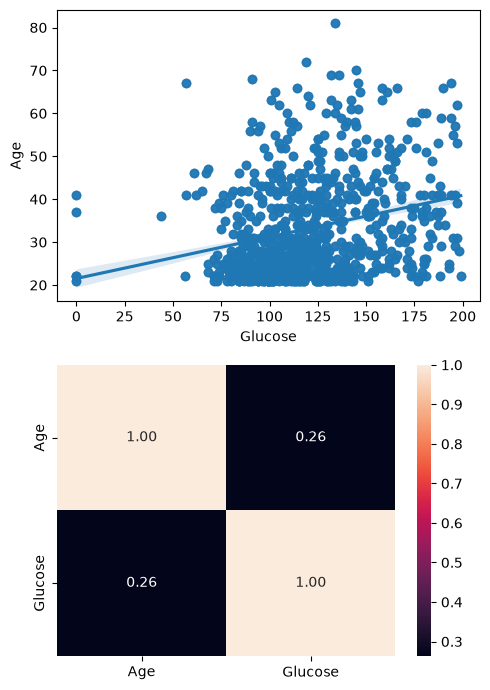

In [90]:
fig, axis = plt.subplots(2, 1, figsize = (5, 7))

# Crear un diagrama de dispersión múltiple
sns.regplot(ax = axis[0], data = total_data, x = "Glucose", y = "Age")
sns.heatmap(total_data[["Age", "Glucose"]].corr(), annot = True, fmt = ".2f", ax = axis[1])

# Ajustar el layout
plt.tight_layout()

# Mostrar el plot
plt.show()

La Glucosa y la Edad están bastante relacionadas a la hora de determinar si alguien tiene Diabetes o no

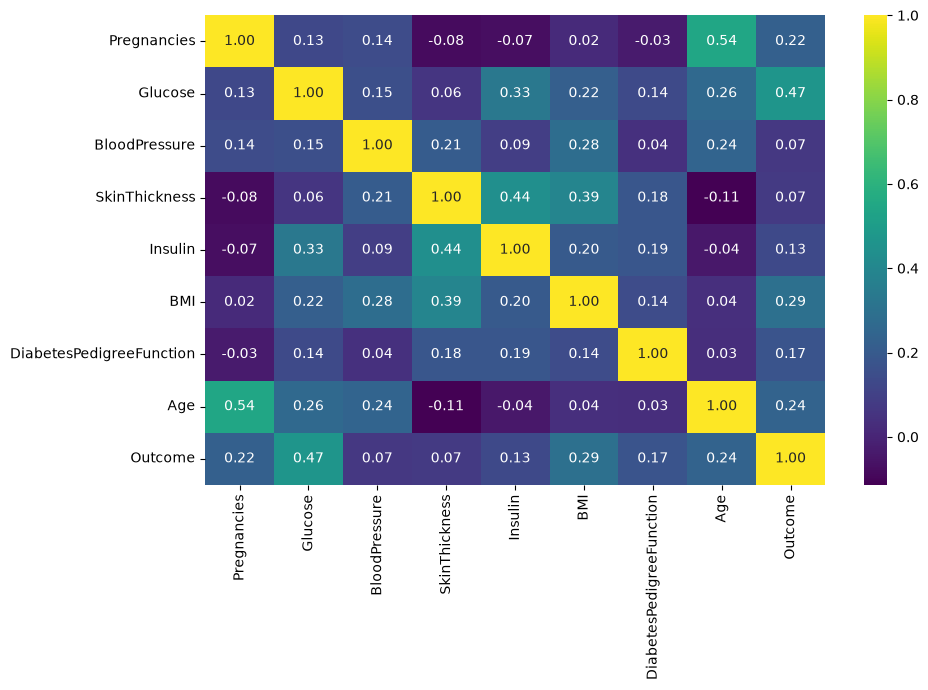

In [91]:
import seaborn as sns
import matplotlib.pyplot as plt

cols_num = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age" , "Outcome"]  # todas numéricas
fig, ax = plt.subplots(figsize=(10,7))
sns.heatmap(total_data[cols_num].corr(method="pearson"), annot=True, fmt=".2f", cmap="viridis", ax=ax)
plt.tight_layout()
plt.show()

# Conclusiones

A simple vista podemos ver que la Edad (age) y su numero de embarazos (Pregnancies) estan altamente vinculadas

La concentración de glucosa en plasma (Glucose) y tener Diabetes (Outcome) están muy relacionadas, lo cual tiene sentido. Pareciera que el indice de masa muscular (BMI) sería lo siguiente que influye

La edad y el grosor del pliegue cutáneo del tríceps (SkinThickness) no estan nada asociadas



In [92]:
# feature engineering
# Análisis de outliers
total_data.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,1536.000000,1536.000000,1536.000000,1536.000000,1536.000000,1536.000000,1536.000000,1536.000000,1536.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.368480,31.962202,19.349501,15.947021,115.206457,7.881592,0.331221,11.756400,0.476796
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


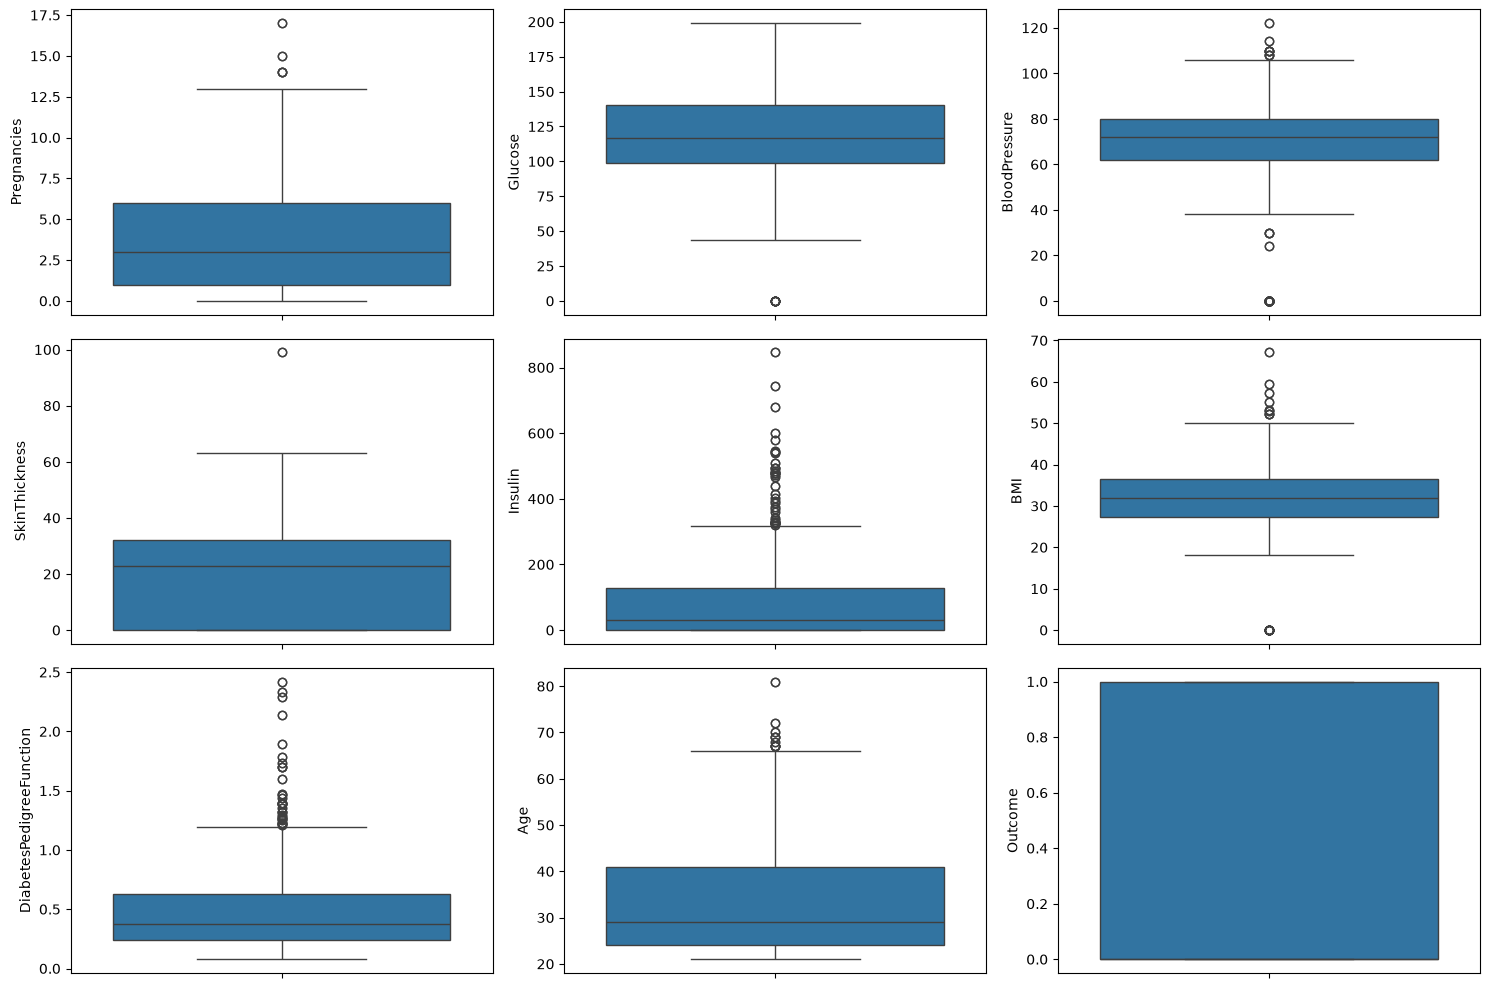

In [93]:
fig, axis = plt.subplots(3, 3, figsize = (15, 10))

sns.boxplot(ax = axis[0, 0], data = total_data, y = "Pregnancies")
sns.boxplot(ax = axis[0, 1], data = total_data, y = "Glucose")
sns.boxplot(ax = axis[0, 2], data = total_data, y = "BloodPressure")
sns.boxplot(ax = axis[1, 0], data = total_data, y = "SkinThickness")
sns.boxplot(ax = axis[1, 1], data = total_data, y = "Insulin")
sns.boxplot(ax = axis[1, 2], data = total_data, y = "BMI")
sns.boxplot(ax = axis[2, 0], data = total_data, y = "DiabetesPedigreeFunction")
sns.boxplot(ax = axis[2, 1], data = total_data, y = "Age")
sns.boxplot(ax = axis[2, 2], data = total_data, y = "Outcome")

plt.tight_layout()

plt.show()

Todas tienen Outliers exccepto Outcome

In [94]:
# Comenzamos con Pregnancies
preg_stats = total_data["Pregnancies"].describe()
preg_stats

count    1536.000000
mean        3.845052
std         3.368480
min         0.000000
25%         1.000000
50%         3.000000
75%         6.000000
max        17.000000
Name: Pregnancies, dtype: float64

In [95]:
preg_iqr = preg_stats["75%"] - preg_stats["25%"]
upper_limit = preg_stats["75%"] + 1.5 * preg_iqr
lower_limit = preg_stats["25%"] - 1.5 * preg_iqr

print(f"Los límites superior e inferior para la búsqueda de outliers son {round(upper_limit, 2)} y {round(lower_limit, 2)}, con un rango intercuartílico de {round(preg_iqr, 2)}")

Los límites superior e inferior para la búsqueda de outliers son 13.5 y -6.5, con un rango intercuartílico de 5.0


In [96]:
# Importes que superan el límite superior (son outliers)
total_data[total_data["Pregnancies"] > 13.5] 

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
88,15,136,70,32,110,37.1,0.153,43,1
159,17,163,72,41,114,40.9,0.817,47,1
298,14,100,78,25,184,36.6,0.412,46,1
455,14,175,62,30,0,33.6,0.212,38,1
856,15,136,70,32,110,37.1,0.153,43,1
927,17,163,72,41,114,40.9,0.817,47,1
1066,14,100,78,25,184,36.6,0.412,46,1
1223,14,175,62,30,0,33.6,0.212,38,1


In [97]:
# igualando los outliers a los limites superiores

from numpy._core.defchararray import upper
# TENEMOS QUE GUARDARNOS TODOS LOS DATASETS, ES DECIR:

total_data_CON_outliers = total_data.copy()
total_data_SIN_outliers = total_data.copy() # Lo vamos a modificar. Para cada variable con outliers, reemplazamos sus valores outliers

outliers_cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness" , "Insulin" , "BMI" , "DiabetesPedigreeFunction" , "Age"]

def replace_outliers(column, df):
  col_stats = total_data[column].describe()
  col_iqr = col_stats["75%"] - col_stats["25%"]
  upper_limit = round(float(col_stats["75%"] + 1.5 * col_iqr), 2)
  lower_limit = round(float(col_stats["25%"] - 1.5 * col_iqr), 2)

  if lower_limit < 0: lower_limit = min(df[column])
  # Vamos a quitar los outliers superiores
  df[column] = df[column].apply(lambda x: x if (x <= upper_limit) else upper_limit)
  # Vamos a quitar los outliers inferiores
  df[column] = df[column].apply(lambda x: x if (x >= lower_limit) else lower_limit)
  return df.copy(), [lower_limit, upper_limit]

outliers_dict = {}
for column in outliers_cols:
  total_data_SIN_outliers, limits = replace_outliers(column, total_data_SIN_outliers)
  outliers_dict.update({column: limits})

outliers_dict # Este JSON me lo tengo que GUARDAR

{'Pregnancies': [0, 13.5],
 'Glucose': [37.12, 202.12],
 'BloodPressure': [35.0, 107.0],
 'SkinThickness': [0, 80.0],
 'Insulin': [0, 318.12],
 'BMI': [13.35, 50.55],
 'DiabetesPedigreeFunction': [0.078, 1.2],
 'Age': [21, 66.5]}

In [98]:
# Nos guardamos el Json de los outliers

import json

with open("./outliers_dict.json", "w") as f:
  json.dump(outliers_dict, f)

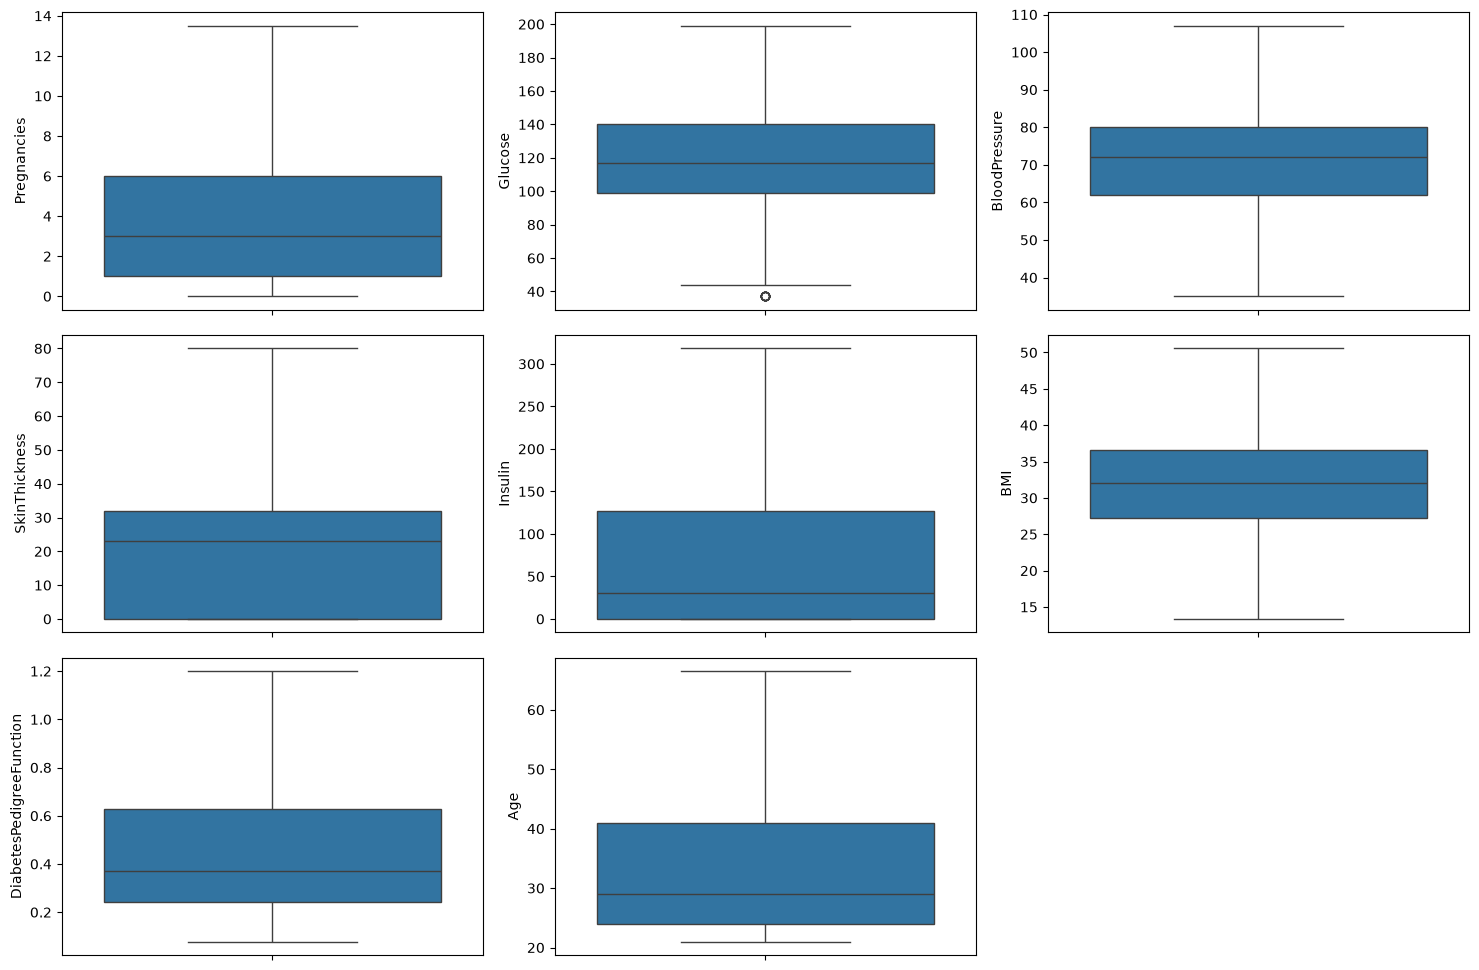

In [99]:
# graficando los outliers metidos en los limites

fig, axis = plt.subplots(3, 3, figsize = (15, 10))

sns.boxplot(ax = axis[0, 0], data = total_data_SIN_outliers, y = "Pregnancies")
sns.boxplot(ax = axis[0, 1], data = total_data_SIN_outliers, y = "Glucose")
sns.boxplot(ax = axis[0, 2], data = total_data_SIN_outliers, y = "BloodPressure")
sns.boxplot(ax = axis[1, 0], data = total_data_SIN_outliers, y = "SkinThickness")
sns.boxplot(ax = axis[1, 1], data = total_data_SIN_outliers, y = "Insulin")
sns.boxplot(ax = axis[1, 2], data = total_data_SIN_outliers, y = "BMI")
sns.boxplot(ax = axis[2, 0], data = total_data_SIN_outliers, y = "DiabetesPedigreeFunction")
sns.boxplot(ax = axis[2, 1], data = total_data_SIN_outliers, y = "Age")




plt.tight_layout()
fig.delaxes(axis[2, 2]) # para ocultar el ultimo

plt.show()

In [100]:
# Análisis de valores faltantes 

total_data_CON_outliers.isnull().sum().sort_values(ascending=False)

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [101]:
# No hay valores faltantes
total_data_SIN_outliers.isnull().sum().sort_values(ascending=False)

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [102]:

# Paso 6: Selección de características
#  Arbol de decision


from sklearn.model_selection import train_test_split

# ESTO ES LO QUE ENTRA EN ESTE PASO
# total_data_SIN_outliers
# total_data_CON_outliers

predictoras = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
target = "Outcome"

X_CON = total_data_CON_outliers.drop(target, axis = 1)[predictoras]
X_SIN = total_data_SIN_outliers.drop(target, axis = 1)[predictoras]
y = total_data_CON_outliers[target]

X_train_CON_outliers, X_test_CON_outliers, y_train, y_test = train_test_split(X_CON, y, test_size = 0.2, random_state = 10) # random_state es la semilla
X_train_SIN_outliers, X_test_SIN_outliers = train_test_split(X_SIN, test_size = 0.2, random_state = 10)

# ESTO ES LO QUE SALE DE ESTE PASO
# X_train_CON_outliers
# X_test_CON_outliers
# X_train_SIN_outliers
# X_test_SIN_outliers
# y_train
# y_test

In [103]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(max_depth=3, random_state=10)

# Entrena con los datos que dividiste en la etapa anterior
tree_model.fit(X_train_SIN_outliers, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",10
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [104]:
#Predicciones 
y_pred = tree_model.predict(X_test_SIN_outliers)

In [105]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# % de acierto
print("Exactitud (Accuracy):", accuracy_score(y_test, y_pred))

#Reporte
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred))

# Matriz de confusión (Aciertos vs Errores)
print("Matriz de Confusión:\n", confusion_matrix(y_test, y_pred))

Exactitud (Accuracy): 0.7662337662337663

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.80      0.87      0.83       203
           1       0.69      0.57      0.62       105

    accuracy                           0.77       308
   macro avg       0.74      0.72      0.73       308
weighted avg       0.76      0.77      0.76       308

Matriz de Confusión:
 [[176  27]
 [ 45  60]]


Accuracy: 0.7662337662337663 no se si es tan bueno

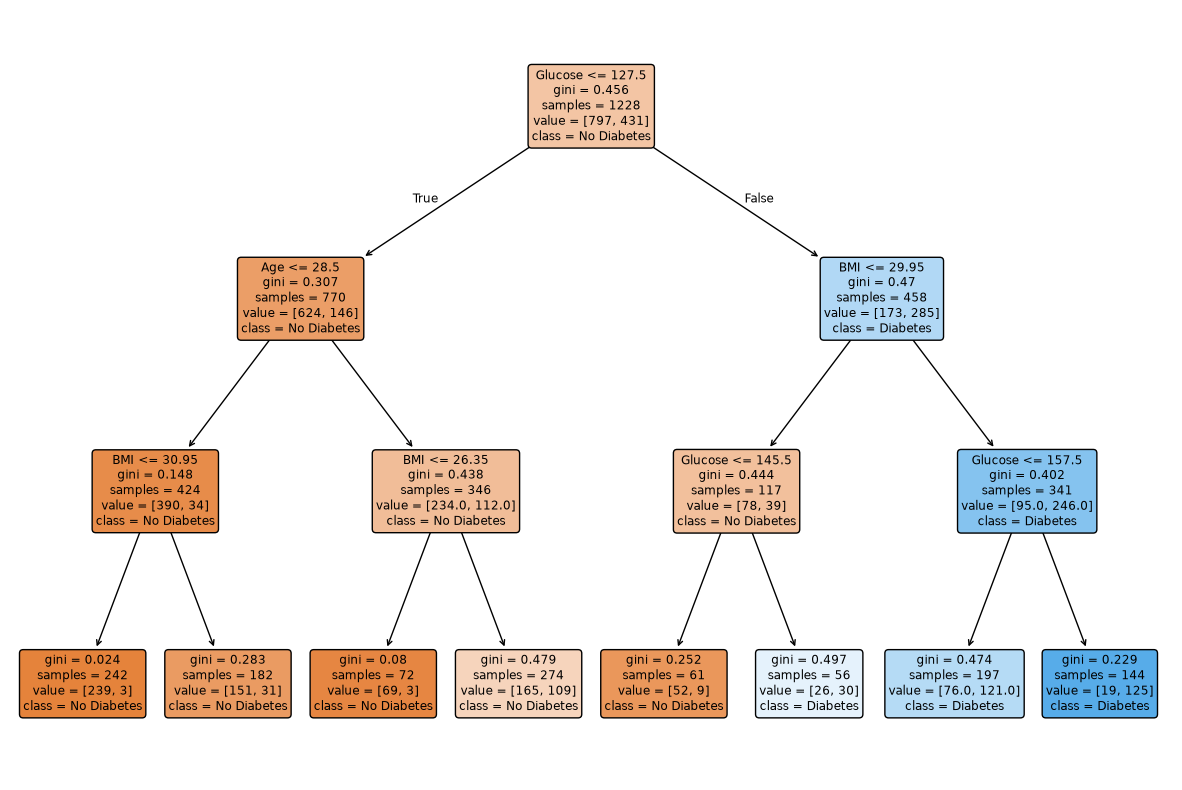

In [106]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(15, 10))
plot_tree(tree_model, feature_names=X_train_SIN_outliers.columns, class_names=['No Diabetes', 'Diabetes'], filled=True, rounded=True)
plt.show()

In [107]:
# Escalado de valores


from sklearn.preprocessing import StandardScaler, MinMaxScaler

# ESTO ES LO QUE ENTRA EN ESTE PASO
# X_train_CON_outliers
# X_test_CON_outliers
# X_train_SIN_outliers
# X_test_SIN_outliers
# y_train
# y_test

## NORMALIZACIÓN (cambiar valores para que tengan media de 0 y std de 1)
### CON OUTLIERS
norm_CON_outliers = StandardScaler()
norm_CON_outliers.fit(X_train_CON_outliers)

X_train_CON_outliers_norm = norm_CON_outliers.transform(X_train_CON_outliers)
X_train_CON_outliers_norm = pd.DataFrame(X_train_CON_outliers_norm, index = X_train_CON_outliers.index, columns = predictoras)

X_test_CON_outliers_norm = norm_CON_outliers.transform(X_test_CON_outliers)
X_test_CON_outliers_norm = pd.DataFrame(X_test_CON_outliers_norm, index = X_test_CON_outliers.index, columns = predictoras)

### SIN OUTLIERS
norm_SIN_outliers = StandardScaler()
norm_SIN_outliers.fit(X_train_SIN_outliers)

X_train_SIN_outliers_norm = norm_SIN_outliers.transform(X_train_SIN_outliers)
X_train_SIN_outliers_norm = pd.DataFrame(X_train_SIN_outliers_norm, index = X_train_SIN_outliers.index, columns = predictoras)

X_test_SIN_outliers_norm = norm_SIN_outliers.transform(X_test_SIN_outliers)
X_test_SIN_outliers_norm = pd.DataFrame(X_test_SIN_outliers_norm, index = X_test_SIN_outliers.index, columns = predictoras)


## ESCALADO MIN-MAX (MINMAXIMIZACIÓN) (cambiar valores para que estén comprendidos entre 0 y 1)
### CON OUTLIERS
scaler_CON_outliers = MinMaxScaler()
scaler_CON_outliers.fit(X_train_CON_outliers)

X_train_CON_outliers_scal = scaler_CON_outliers.transform(X_train_CON_outliers)
X_train_CON_outliers_scal = pd.DataFrame(X_train_CON_outliers_scal, index = X_train_CON_outliers.index, columns = predictoras)

X_test_CON_outliers_scal = scaler_CON_outliers.transform(X_test_CON_outliers)
X_test_CON_outliers_scal = pd.DataFrame(X_test_CON_outliers_scal, index = X_test_CON_outliers.index, columns = predictoras)

### SIN OUTLIERS
scaler_SIN_outliers = MinMaxScaler()
scaler_SIN_outliers.fit(X_train_SIN_outliers)

X_train_SIN_outliers_scal = scaler_SIN_outliers.transform(X_train_SIN_outliers)
X_train_SIN_outliers_scal = pd.DataFrame(X_train_SIN_outliers_scal, index = X_train_SIN_outliers.index, columns = predictoras)

X_test_SIN_outliers_scal = scaler_SIN_outliers.transform(X_test_SIN_outliers)
X_test_SIN_outliers_scal = pd.DataFrame(X_test_SIN_outliers_scal, index = X_test_SIN_outliers.index, columns = predictoras)

# ESTO ES LO QUE SALE DE ESTE PASO
# X_train_CON_outliers
# X_train_CON_outliers_norm
# X_train_CON_outliers_scal

# X_train_SIN_outliers
# X_train_SIN_outliers_norm
# X_train_SIN_outliers_scal

# X_test_CON_outliers
# X_test_CON_outliers_norm
# X_test_CON_outliers_scal

# X_test_SIN_outliers
# X_test_SIN_outliers_norm
# X_test_SIN_outliers_scal

# y_train
# y_test

In [108]:
X_train_CON_outliers

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
573,2,98,60,17,120,34.7,0.198,22
222,7,119,0,0,0,25.2,0.209,37
1157,3,100,68,23,81,31.6,0.949,28
916,5,147,78,0,0,33.7,0.218,65
1184,1,97,68,21,0,27.2,1.095,22
...,...,...,...,...,...,...,...,...
1393,4,90,88,47,54,37.7,0.362,29
1344,6,108,44,20,130,24.0,0.813,35
527,3,116,74,15,105,26.3,0.107,24
1149,0,105,68,22,0,20.0,0.236,22


In [109]:
X_train_CON_outliers_norm

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
573,-0.549935,-0.715429,-0.455562,-0.222161,0.374516,0.355872,-0.840395,-0.969165
222,0.936900,-0.057013,-3.555474,-1.294742,-0.692488,-0.893859,-0.806704,0.324460
1157,-0.252568,-0.652723,-0.042241,0.156397,0.027739,-0.051935,1.459791,-0.451715
916,0.342166,0.820876,0.474411,-1.294742,-0.692488,0.224322,-0.779139,2.739226
1184,-0.847303,-0.746782,-0.042241,0.030211,-0.692488,-0.630757,1.906964,-0.969165
...,...,...,...,...,...,...,...,...
1393,0.044799,-0.966254,0.991063,1.670628,-0.212336,0.750524,-0.338091,-0.365474
1344,0.639533,-0.401898,-1.282205,-0.032882,0.463432,-1.051720,1.043246,0.151976
527,-0.252568,-0.151072,0.267750,-0.348347,0.241140,-0.749153,-1.119113,-0.796682
1149,-1.144670,-0.495957,-0.042241,0.093304,-0.692488,-1.577922,-0.724008,-0.969165


In [110]:
X_train_CON_outliers_scal

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
573,0.117647,0.494949,0.491803,0.171717,0.141844,0.517139,0.051238,0.016667
222,0.411765,0.601010,0.000000,0.000000,0.000000,0.375559,0.055935,0.266667
1157,0.176471,0.505051,0.557377,0.232323,0.095745,0.470939,0.371904,0.116667
916,0.294118,0.742424,0.639344,0.000000,0.000000,0.502235,0.059778,0.733333
1184,0.058824,0.489899,0.557377,0.212121,0.000000,0.405365,0.434244,0.016667
...,...,...,...,...,...,...,...,...
1393,0.235294,0.454545,0.721311,0.474747,0.063830,0.561848,0.121264,0.133333
1344,0.352941,0.545455,0.360656,0.202020,0.153664,0.357675,0.313834,0.233333
527,0.176471,0.585859,0.606557,0.151515,0.124113,0.391952,0.012383,0.050000
1149,0.000000,0.530303,0.557377,0.222222,0.000000,0.298063,0.067464,0.016667


In [111]:
# GUARDARLO -> TODO <-

# RECORDAR HABER GUARDADO LOS JSONS DE LA FACTORIZACIÓN
#  si se rompe poner en la terminal pip install openpyxl

import os

# PATH = "/data/processed"
PATH = "../data/processed"

# DATASETS QUE HE IDO ACUMULANDO EN LOS PASOS 4 Y 5
X_train_CON_outliers.to_excel(f"{PATH}/X_train_CON_outliers.xlsx", index = False)
X_train_CON_outliers_norm.to_excel(f"{PATH}/X_train_CON_outliers_norm.xlsx", index = False)
X_train_CON_outliers_scal.to_excel(f"{PATH}/X_train_CON_outliers_scal.xlsx", index = False)
X_train_SIN_outliers.to_excel(f"{PATH}/X_train_SIN_outliers.xlsx", index = False)
X_train_SIN_outliers_norm.to_excel(f"{PATH}/X_train_SIN_outliers_norm.xlsx", index = False)
X_train_SIN_outliers_scal.to_excel(f"{PATH}/X_train_SIN_outliers_scal.xlsx", index = False)

X_test_CON_outliers.to_excel(f"{PATH}/X_test_CON_outliers.xlsx", index = False)
X_test_CON_outliers_norm.to_excel(f"{PATH}/X_test_CON_outliers_norm.xlsx", index = False)
X_test_CON_outliers_scal.to_excel(f"{PATH}/X_test_CON_outliers_scal.xlsx", index = False)
X_test_SIN_outliers.to_excel(f"{PATH}/X_test_SIN_outliers.xlsx", index = False)
X_test_SIN_outliers_norm.to_excel(f"{PATH}/X_test_SIN_outliers_norm.xlsx", index = False)
X_test_SIN_outliers_scal.to_excel(f"{PATH}/X_test_SIN_outliers_scal.xlsx", index = False)

y_train.to_excel(f"{PATH}/y_train.xlsx", index = False)
y_test.to_excel(f"{PATH}/y_test.xlsx", index = False)

# SCALERS
import pickle

# MODEL_PATH = "./model"
MODEL_PATH = "../models"

with open(f"{MODEL_PATH}/norm_CON_outliers.pkl", "wb") as file:
  pickle.dump(norm_CON_outliers, file)
with open(f"{MODEL_PATH}/norm_SIN_outliers.pkl", "wb") as file:
  pickle.dump(norm_SIN_outliers, file)
with open(f"{MODEL_PATH}/scaler_CON_outliers.pkl", "wb") as file:
  pickle.dump(scaler_CON_outliers, file)
with open(f"{MODEL_PATH}/scaler_SIN_outliers.pkl", "wb") as file:
  pickle.dump(scaler_SIN_outliers, file)